# UMAP: A Faster Map That Can Transform New Rows

**Family:** Unsupervised learning | **Level:** Intermediate | **Dataset:** `digits` | **Runs on:** CPU, about 1 minute(s)

Embed with a fuzzy neighbour graph and apply the map to unseen data.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How UMAP builds a fuzzy graph
- How n_neighbors and min_dist shape the map
- How to transform held out rows
- How UMAP compares with t-SNE and PCA

**Prerequisites:**

- Distances and vectors
- Standardising features

**Skills you will have afterwards:**

- Pick settings without labels
- Check stability
- Compare with a reference labelling

## 2. Real-World Problem

**Context.** Maps of embeddings must often be applied to new data as it arrives.

**The problem.** Embed digit images and project held out digits into the same map.

**Why it matters.** A transform lets a monitoring system place new items without refitting.

**Why machine learning.** Local structure of images is nonlinear.

**Why this algorithm.** UMAP is fast, keeps more global structure than t-SNE and supports `transform`.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### UMAP: Uniform Manifold Approximation and Projection

- **Type:** foundational paper
- **Authors:** McInnes, L., Healy, J., Saul, N. and Grossberger, L.
- **Year and venue:** 2018, Journal of Open Source Software 3(29):861
- **DOI or URL:** https://doi.org/10.21105/joss.00861
- **Verification:** Crossref 2026-11-17 (title, year, volume, 4 authors)
- **Research objective:** Software paper for the UMAP dimension reduction algorithm.
- **Methodology:** Fuzzy topological graph and cross entropy layout optimisation.
- **Dataset:** See the arXiv paper.
- **Main findings:** Describes the open source implementation.
- **Limitations:** Software description, not the theory paper.

### UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction

- **Type:** foundational paper
- **Authors:** McInnes, L., Healy, J. and Melville, J.
- **Year and venue:** 2018, arXiv:1802.03426
- **DOI or URL:** https://arxiv.org/abs/1802.03426
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Present the theory and algorithm of UMAP.
- **Methodology:** Fuzzy simplicial sets built from nearest neighbours, then layout optimisation.
- **Dataset:** Benchmarks including MNIST and Fashion-MNIST.
- **Main findings:** Reports speed and structure preservation competitive with t-SNE.
- **Limitations:** Preprint. Distances in the embedding are not directly interpretable.

**Relationship to this notebook.** McInnes et al. introduce UMAP. We use the `umap-learn` package, version recorded in the experiment record. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Local fuzzy sets.** For point $i$ with nearest neighbour distance $\rho_i$, edge weight $w_{ij} = \exp\big(-(d_{ij}-\rho_i)/\sigma_i\big)$ with $\sigma_i$ such that $\sum_j w_{ij} = \log_2 k$. Symmetrise: $w = w_{ij} + w_{ji} - w_{ij}w_{ji}$.

**Low dimensional weights.** $q_{ij} = (1 + a\lVert y_i-y_j\rVert^{2b})^{-1}$ with $a, b$ fitted from `min_dist`.

**Objective.** Minimise the cross entropy between weights $w$ and $q$ by stochastic gradient descent with negative sampling.

**Limits.** Parameters shape the picture, global distances are only partly kept.

## 5. Dataset Introduction

**Optical Recognition of Handwritten Digits**, UCI, licence CC BY 4.0, DOI 10.24432/C50P49. scikit-learn ships 1797 images (the test part of the UCI data) as 8 by 8 grids, so 64 integer pixel features from 0 to 16. Target `digit`, ten classes. Limit: far smaller than MNIST.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from ml_lab.data import load_dataset
from ml_lab.evaluation import internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "umap"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

bundle = load_dataset("digits")
X_raw = bundle.X
y_true = bundle.y          # evaluation only
print("shape:", X_raw.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
shape: (1797, 64)


,source
title,Optical Recognition of Handwritten Digits
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/80/optical...
license,CC BY 4.0
doi,10.24432/C50P49
rows,1797
features,64
limits,"8x8 images, much smaller than MNIST."


## 6. Exploratory Data Analysis

We check size, missing values, label balance and feature relations. The reference labels are used for evaluation only, never for fitting. 

Rows and columns: (1797, 64)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
pixel_0_0,1797.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
pixel_0_1,1797.0,0.304,0.907,0.0,0.0,0.0,0.0,8.0
pixel_0_2,1797.0,5.205,4.755,0.0,1.0,4.0,9.0,16.0
pixel_0_3,1797.0,11.836,4.249,0.0,10.0,13.0,15.0,16.0
pixel_0_4,1797.0,11.848,4.287,0.0,10.0,13.0,15.0,16.0
pixel_0_5,1797.0,5.782,5.666,0.0,0.0,4.0,11.0,16.0
pixel_0_6,1797.0,1.362,3.326,0.0,0.0,0.0,0.0,16.0
pixel_0_7,1797.0,0.130,1.037,0.0,0.0,0.0,0.0,15.0
pixel_1_0,1797.0,0.006,0.094,0.0,0.0,0.0,0.0,2.0
pixel_1_1,1797.0,1.994,3.196,0.0,0.0,0.0,3.0,16.0


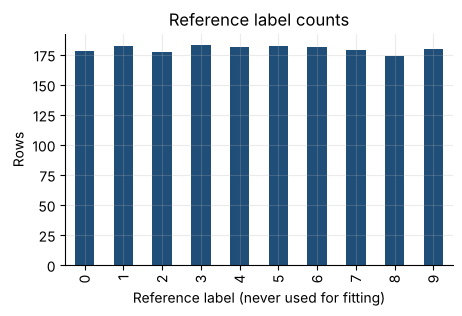

Mean absolute correlation between features: nan


In [2]:
print("Rows and columns:", X_raw.shape)
print("Missing values:", int(X_raw.isna().sum().sum()))
display(X_raw.describe().T.head(15).round(3))
fig, ax = plt.subplots(figsize=(5, 3))
pd.Series(y_true).value_counts().sort_index().plot.bar(ax=ax)
ax.set_xlabel("Reference label (never used for fitting)"); ax.set_ylabel("Rows"); ax.set_title("Reference label counts")
plt.show()
corr = X_raw.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print("Mean absolute correlation between features:", round(float(corr.mean()), 3))

## 7. Data Preprocessing

Split first: 70 percent of rows fit the map, 30 percent are transformed to test the out of sample map. Pixels are scaled to 0 to 1.

In [3]:
from sklearn.model_selection import train_test_split
X_tr, X_te, y_tr, y_te = train_test_split(X_raw.values / 16.0, y_true.values, test_size=0.3, stratify=y_true, random_state=SEED)
print(X_tr.shape, X_te.shape)

(1257, 64) (540, 64)


## 8. Algorithm Implementation

### 8.1 Concept

UMAP finds a low dimensional layout whose neighbour graph looks like the high dimensional one.

### 8.2 Python implementation from scratch

We compute the fuzzy edge weights for one row to show the local construction. The full optimisation is not reimplemented.

In [4]:
from sklearn.neighbors import NearestNeighbors
K = 15
nn = NearestNeighbors(n_neighbors=K + 1).fit(X_tr)
dist, idx = nn.kneighbors(X_tr[:1])
d = dist[0, 1:]
rho = d[0]
lo, hi = 1e-3, 1e3
for _ in range(60):
    sigma = (lo + hi) / 2
    total = np.exp(-(d - rho) / sigma).sum()
    if total > np.log2(K):
        hi = sigma
    else:
        lo = sigma
w = np.exp(-(d - rho) / sigma)
print("rho:", round(float(rho), 3), "| sigma:", round(float(sigma), 3), "| sum of weights:", round(float(w.sum()), 3), "| target log2(k):", round(float(np.log2(K)), 3))
print("weights of the 15 neighbours:", np.round(w, 2))

rho: 1.066 | sigma: 0.294 | sum of weights: 3.907 | target log2(k): 3.907
weights of the 15 neighbours: [1.   0.44 0.4  0.35 0.32 0.24 0.17 0.16 0.14 0.14 0.13 0.12 0.11 0.1
 0.08]


### 8.3 Library implementation

scikit-learn and scipy provide tested implementations.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `n_neighbors` | Local neighbourhood size. Larger values keep more global structure. |
| `min_dist` | How tightly points may pack. |
| `metric` | Distance. |
| `random_state` | Fixes the result but turns off parallelism. |

## 9. Model Training

We fit UMAP on training rows for a small grid of n_neighbors and min_dist and choose by trustworthiness on the training rows.

In [5]:
import umap
from sklearn.manifold import trustworthiness
rows, models = [], {}
for nn_ in [5, 15, 50]:
    for md in [0.0, 0.1, 0.5]:
        m = umap.UMAP(n_neighbors=nn_, min_dist=md, random_state=SEED).fit(X_tr)
        models[(nn_, md)] = m
        rows.append({"n_neighbors": nn_, "min_dist": md, "trustworthiness": trustworthiness(X_tr, m.embedding_, n_neighbors=10)})
sweep = pd.DataFrame(rows)
display(sweep.round(4))
best = sweep.loc[sweep.trustworthiness.idxmax()]
model = models[(int(best.n_neighbors), float(best.min_dist))]
emb_tr = model.embedding_
emb_te = model.transform(X_te)

,n_neighbors,min_dist,trustworthiness
0,5,0.0,0.9875
1,5,0.1,0.9869
2,5,0.5,0.9829
3,15,0.0,0.9880
4,15,0.1,0.9878
5,15,0.5,0.9850
6,50,0.0,0.9864
7,50,0.1,0.9843
8,50,0.5,0.9788


## 10. Evaluation

Trustworthiness on training rows, trustworthiness of the transformed held out rows, and a 5-nearest-neighbour classifier trained on training embeddings and scored on held out embeddings (labels used for evaluation only).

In [6]:
from sklearn.neighbors import KNeighborsClassifier
acc = KNeighborsClassifier(5).fit(emb_tr, y_tr).score(emb_te, y_te)
pca_m = PCA(2, random_state=SEED).fit(X_tr)
acc_pca = KNeighborsClassifier(5).fit(pca_m.transform(X_tr), y_tr).score(pca_m.transform(X_te), y_te)
METRICS = {"trustworthiness_train": float(best.trustworthiness), "trustworthiness_heldout": float(trustworthiness(X_te, emb_te, n_neighbors=10)),
           "knn_accuracy_heldout_umap": float(acc), "knn_accuracy_heldout_pca2": float(acc_pca)}
CONFIG = {"n_neighbors": int(best.n_neighbors), "min_dist": float(best.min_dist)}
EXTRA = {"sweep": sweep.round(4).to_dict("records")}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="unsupervised", algorithm="UMAP", dataset="digits",
                          task="clustering", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

saved: /home/claude/open-python/experiments/results/umap.json


,metric
trustworthiness_train,0.9880
trustworthiness_heldout,0.9796
knn_accuracy_heldout_umap,0.9778
knn_accuracy_heldout_pca2,0.6241


## 11. Visualization

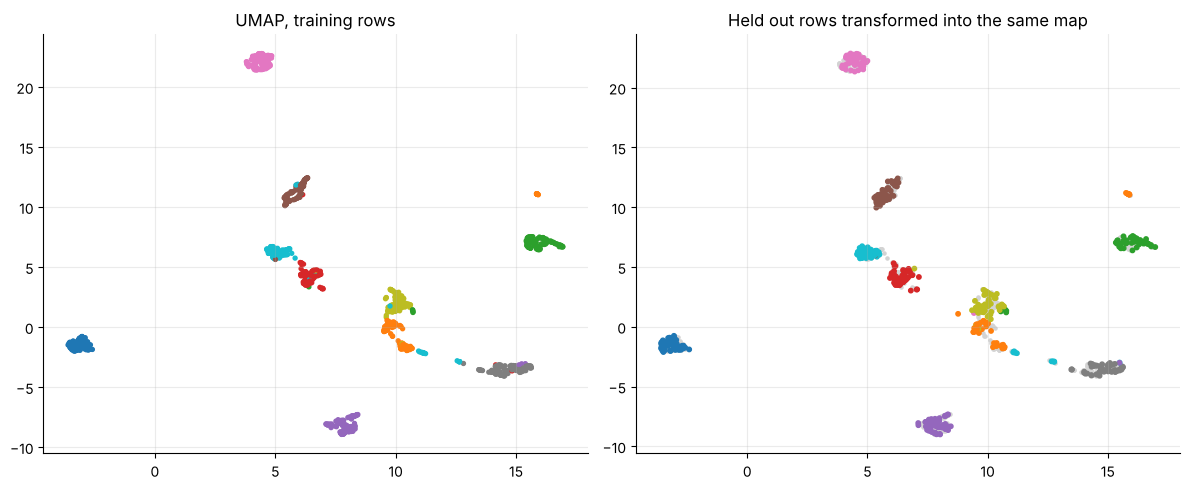

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(emb_tr[:, 0], emb_tr[:, 1], c=y_tr, cmap="tab10", s=8); axes[0].set_title("UMAP, training rows")
axes[1].scatter(emb_tr[:, 0], emb_tr[:, 1], c="lightgray", s=5)
axes[1].scatter(emb_te[:, 0], emb_te[:, 1], c=y_te, cmap="tab10", s=10); axes[1].set_title("Held out rows transformed into the same map")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "overview"); plt.show()

## 12. Interpretation

Held out digits should land in the region of their own digit. Misplaced points are listed below.

In [8]:
pred = KNeighborsClassifier(5).fit(emb_tr, y_tr).predict(emb_te)
wrong = np.where(pred != y_te)[0]
print("held out rows landing in another digit's region:", len(wrong), "of", len(y_te))
print(pd.crosstab(pd.Series(y_te[wrong], name="true digit"), pd.Series(pred[wrong], name="map region")).head(10))

held out rows landing in another digit's region: 12 of 540
map region  1  2  3  4  7  8  9
true digit                     
1           0  0  0  0  0  1  0
4           0  0  0  0  1  0  0
5           0  0  0  0  0  0  1
6           0  0  0  0  0  1  0
7           0  0  0  1  0  0  0
8           4  1  1  0  0  0  0
9           0  0  0  0  1  0  0


## 13. Experiments and Challenges

### Experiment 1: n_neighbors effect

Local versus global structure.

In [9]:
for (nn_, md), m in models.items():
    if md == 0.1:
        print(f"n_neighbors={nn_}: trustworthiness {trustworthiness(X_tr, m.embedding_, n_neighbors=10):.4f}")

n_neighbors=5: trustworthiness 0.9869
n_neighbors=15: trustworthiness 0.9878
n_neighbors=50: trustworthiness 0.9843


### Experiment 2: Seed variability

Report the spread across seeds.

In [10]:
vals = []
for s in range(3):
    m = umap.UMAP(n_neighbors=int(best.n_neighbors), min_dist=float(best.min_dist), random_state=s).fit(X_tr)
    vals.append(trustworthiness(X_tr, m.embedding_, n_neighbors=10))
print("trustworthiness by seed:", np.round(vals, 4))

trustworthiness by seed: [0.9885 0.9878 0.9877]


### Experiment 3: UMAP versus t-SNE run time

Wall clock on the same training rows.

In [11]:
import time
from sklearn.manifold import TSNE
t = time.time(); umap.UMAP(random_state=SEED).fit(X_tr); a = time.time() - t
t = time.time(); TSNE(2, init="pca", random_state=SEED).fit(PCA(30, random_state=SEED).fit_transform(X_tr)); b = time.time() - t
print(f"UMAP {a:.1f} s, t-SNE {b:.1f} s on {len(X_tr)} rows (first UMAP call includes compilation time)")

UMAP 1.2 s, t-SNE 2.3 s on 1257 rows (first UMAP call includes compilation time)


### Exercises for learners

1. Repeat with `SEED = 7` and report which numbers move.
2. Change the number of rows by sampling 50 percent and compare the result.
3. Add pure noise columns and watch the internal scores.

## 14. Research Discussion

The UMAP paper claims better run time and global structure than t-SNE. Our run time test covers one small dataset only, so it cannot confirm scaling claims.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use supervised UMAP, report stability over seeds, and evaluate global structure with distance correlation.

**Research limitations.** One dataset and one seed for the headline numbers. 

## 15. Summary and Further Reading

**Key takeaways**

- UMAP supports transform.
- n_neighbors trades local for global structure.
- Always check the map with trustworthiness.

**Use cases.** Embedding visualisation, preprocessing before clustering.

**Limitations.** Parameter dependent pictures.

**Recommended next notebook.** Isolation Forest.

**Further reading.** See `references.md` in this folder.